# Tiamat — classificação de candidatos a exoplanetas

**Autor:** Gustavo Placido Aniceto da Silva  
**Instituição:** Ilum Escola de Ciência — CNPEM  

Este caderno estuda a reprodução de `koi_pdisposition` a partir de 25 atributos. Candidato não significa planeta confirmado. São comparados Dummy, regressão logística, k-NN sem PCA, k-NN com PCA, árvore, Random Forest e HistGradientBoosting.

**Limite da evidência:** esta base já foi usada no desenvolvimento anterior. O holdout abaixo é reservado na execução revisada, mas não é um catálogo externo nem uma amostra historicamente inédita. Nenhuma reorganização apaga o conhecimento anterior sobre os dados.

## 1. Contexto científico e alvo

O trânsito é uma queda de brilho causada pela passagem de um objeto diante da estrela na linha de visão. Profundidade, duração e repetição do sinal ajudam a caracterizar o sistema [1]. A classificação exige descartar explicações alternativas: sistemas estelares eclipsantes, contaminação e sinais instrumentais. Thompson et al. descrevem o catálogo DR25, o Robovetter e a avaliação de completude e confiabilidade [2].

`koi_pdisposition` descreve a disposição baseada nos dados Kepler: `CANDIDATE` passou pela triagem aplicável e `FALSE POSITIVE` foi rejeitado. Esses rótulos podem mudar e não equivalem a confirmação física [3]. O problema deste caderno é: **quanto um procedimento de aprendizado supervisionado consegue reproduzir essa triagem em objetos de estrelas não presentes no ajuste?**

Os atributos são medidas e estimativas já extraídas do catálogo; Algumas grandezas compartilham informação por relações físicas e hipóteses do ajuste de trânsito [4]. Há precedentes de aprendizado de máquina em exoplanetas, como a rede convolucional de Shallue e Vanderburg [5], mas sua tarefa e representação diferem deste estudo tabular.

## 2. Bibliotecas, configuração e reprodutibilidade

Pandas organiza as tabelas; NumPy faz cálculos; Matplotlib/Seaborn desenham os resultados; scikit-learn fornece transformações, classificadores e métricas; Optuna otimiza os hiperparâmetros [6–17]. As versões efetivamente utilizadas são registradas, pois uma semente não garante resultados idênticos entre versões ou plataformas.

O orçamento é **100 tentativas por família em cada busca**. Isso não significa 100 configurações únicas: o código conta as configurações distintas e os estados das tentativas. São utilizados três folds internos para controlar o custo da validação aninhada; os cinco folds externos avaliam generalização. A semente, os espaços de busca e o orçamento são definidos antes de acessar os escores de teste.

In [1]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn optuna joblib threadpoolctl
import os

for chave in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[chave] = "1"
import sys, json, hashlib, platform, time, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from optuna.trial import TrialState
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    PrecisionRecallDisplay,
)
from sklearn.inspection import permutation_importance
from joblib import parallel_backend, dump
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Configuração do experimento

As sementes, o orçamento e as famílias de modelos são definidos antes da avaliação no conjunto de teste.

A constante `SEMENTE` controla os sorteios reproduzíveis. `N_EXTERNO` e `N_INTERNO` definem as divisões da validação; `N_TRIALS` estabelece o número de tentativas por busca. A grade de limiares determina quais regras de decisão serão comparadas. Essas escolhas ficam explícitas para que o experimento possa ser acompanhado e repetido sem depender de valores espalhados pelo código.

In [2]:
SEMENTE = 42
N_EXTERNO, N_INTERNO, N_TRIALS = 5, 3, 100
N_JOBS, N_BOOTSTRAP = 4, 1000
GRADE_LIMIAR = np.unique(np.r_[np.linspace(0.10, 0.90, 33), 0.5])
FAMILIAS = [
    "Logística",
    "k-NN sem PCA",
    "k-NN + PCA",
    "Árvore",
    "Floresta",
    "Boosting",
]
CAMINHO_CSV = Path("Dataset Exoplanetas.csv")
if not CAMINHO_CSV.exists():
    CAMINHO_CSV = Path("data/Dataset Exoplanetas.csv")
if not CAMINHO_CSV.exists():
    raise FileNotFoundError(
        "Disponibilize Dataset Exoplanetas.csv ou ajuste CAMINHO_CSV."
    )


### Versões das bibliotecas

As versões são registradas para interpretar a reprodutibilidade da execução.

A tabela informa a versão instalada de cada dependência. Ela ajuda a identificar diferenças de ambiente que podem afetar o treinamento ou a apresentação dos gráficos. A célula também configura a exibição de tabelas, a aparência das figuras e a quantidade de mensagens emitidas pelo Optuna; essas configurações facilitam a leitura das próximas saídas.

In [3]:
VERSOES = {
    p: version(p)
    for p in [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "optuna",
        "matplotlib",
        "seaborn",
        "joblib",
        "threadpoolctl",
    ]
}
print("Python:", sys.version)
display(pd.Series(VERSOES, name="versão").to_frame())
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_colwidth", 240)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")


Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


,versão
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
optuna,5.0.0
matplotlib,3.11.2
seaborn,0.13.2
joblib,1.6.0
threadpoolctl,3.6.0


## 3. Auditoria dos registros e tratamento de ausências

O esquema é validado antes da seleção das colunas; rótulos inesperados interrompem a execução em vez de virarem zero. Identificadores ausentes também interrompem o processo. Duplicatas exatas são removidas de forma rastreável; um mesmo KOI com registros diferentes exige revisão e gera erro. Identificadores são usados para auditoria e grupos, nunca como preditores. Também são contabilizados vetores de atributos repetidos e assinaturas com classes diferentes; esses registros não são removidos automaticamente, pois medidas iguais não provam que sejam o mesmo objeto.

Valores não numéricos e infinitos são contados e convertidos para ausentes. Quantidades estritamente positivas com valores não positivos e valores fora de limites geométricos elementares são sinalizados e tratados como ausentes. Um objeto não é descartado apenas por apresentar um raio ajustado elevado: falsos positivos podem produzir ajustes planetários estranhos. A regra é fixa, não usa percentis calculados sobre o teste. Valores extremos restantes são preservados e descritos no treino.

A mediana de cada coluna será aprendida por `SimpleImputer` **dentro do pipeline de cada fold** [6,7]. Essa escolha mantém objetos incompletos, mas não resolve automaticamente ausências informativas. A comparação por completude na avaliação final será descritiva. Esta versão não utiliza indicadores de ausência, preservando exatamente as 25 entradas antes do PCA.

In [4]:
ATRIBUTOS = [
    "koi_gmag",
    "koi_rmag",
    "koi_jmag",
    "koi_hmag",
    "koi_kmag",
    "koi_kepmag",
    "koi_num_transits",
    "koi_max_sngle_ev",
    "koi_max_mult_ev",
    "koi_model_snr",
    "koi_prad",
    "koi_impact",
    "koi_duration",
    "koi_depth",
    "koi_period",
    "koi_ror",
    "koi_dor",
    "koi_incl",
    "koi_teq",
    "koi_steff",
    "koi_slogg",
    "koi_srad",
    "koi_smass",
    "koi_insol",
    "koi_srho",
]
TARGET, GRUPO, OBJETO = "koi_pdisposition", "kepid", "kepoi_name"


### Carregando os dados

O CSV é lido com pandas, seguido da verificação das colunas e dos identificadores.

O arquivo é carregado em `bruto`, preservando uma referência aos registros recebidos. Antes da análise, são verificadas a presença das colunas exigidas, a correspondência dos rótulos às duas classes esperadas e a integridade dos identificadores. Em seguida, as duplicatas exatas são removidas. Registros diferentes associados ao mesmo objeto interrompem a execução, pois exigem uma decisão sobre a fonte dos dados antes do treinamento.

In [5]:
HASH_DADOS = hashlib.sha256(CAMINHO_CSV.read_bytes()).hexdigest()
bruto = pd.read_csv(CAMINHO_CSV, comment="#")
faltantes = set(ATRIBUTOS + [TARGET, GRUPO, OBJETO]) - set(bruto.columns)
if faltantes:
    raise ValueError(f"Colunas ausentes: {sorted(faltantes)}")
if bruto[[TARGET, GRUPO, OBJETO]].isna().any().any():
    raise ValueError("Há alvo/identificador ausente; revise a fonte.")
rotulos = set(bruto[TARGET].unique())
if rotulos != {"CANDIDATE", "FALSE POSITIVE"}:
    raise ValueError(f"Classes inesperadas ou classe ausente: {rotulos}")
duplicatas_exatas = int(bruto.duplicated().sum())
dados = bruto.drop_duplicates().copy()
if dados[OBJETO].duplicated().any():
    raise ValueError(
        "KOI repetido com registros diferentes; resolva antes de dividir."
    )
# Identificadores preservados como strings; cada linha mantém um ID rastreável.
dados[GRUPO] = dados[GRUPO].astype(str)
dados[OBJETO] = dados[OBJETO].astype(str)


### Tratamento dos atributos

As regras abaixo transformam valores inválidos em ausentes; a imputação será ajustada somente no treino.

Cada coluna é convertida para valores numéricos. O código distingue ausências já existentes, entradas não numéricas, infinitos e valores incompatíveis com as regras físicas adotadas. Esses casos ficam registrados na tabela de auditoria. Substituir uma entrada inválida por um valor ausente permite conservar o objeto e tratar essa ausência no pipeline, sem calcular medianas com informações da validação ou do teste.

In [6]:
auditoria = []
positivos = set(
    [
        "koi_period",
        "koi_duration",
        "koi_prad",
        "koi_ror",
        "koi_dor",
        "koi_teq",
        "koi_steff",
        "koi_srad",
        "koi_smass",
        "koi_srho",
    ]
)
for col in ATRIBUTOS:
    original = dados[col]
    numerico = pd.to_numeric(original, errors="coerce")
    nao_numerico = int((original.notna() & numerico.isna()).sum())
    infinito = int(np.isinf(numerico).sum())
    numerico = numerico.replace([np.inf, -np.inf], np.nan)
    invalido = pd.Series(False, index=dados.index)
    if col in positivos:
        invalido |= numerico <= 0
    if col in ["koi_impact", "koi_num_transits", "koi_insol"]:
        invalido |= numerico < 0
    if col == "koi_depth":
        invalido |= (numerico < 0) | (numerico > 1e6)
    if col == "koi_incl":
        invalido |= (numerico < 0) | (numerico > 180)
    if col == "koi_num_transits":
        invalido |= numerico.notna() & (numerico % 1 != 0)
    dados[col] = numerico.mask(invalido)
    auditoria.append(
        {
            "atributo": col,
            "ausentes_originais": int(original.isna().sum()),
            "não_numéricos": nao_numerico,
            "infinitos": infinito,
            "fora_da_regra": int(invalido.sum()),
            "ausentes_finais": int(dados[col].isna().sum()),
        }
    )


### Separando atributos e target

X contém as 25 entradas. O target y usa 0 para falso positivo e 1 para candidato.

As linhas de `X`, `y` e `grupos` permanecem na mesma ordem: cada posição descreve o mesmo objeto. `grupos` guarda o identificador da estrela para controlar as partições, mas não entra como atributo preditivo. A redefinição do índice facilita selecionar as mesmas observações nas três estruturas durante a validação cruzada.

In [7]:
dados = dados.reset_index(drop=True)
y = (
    dados[TARGET]
    .map({"FALSE POSITIVE": 0, "CANDIDATE": 1})
    .astype(int)
    .to_numpy()
)
X = dados[ATRIBUTOS].copy()
grupos = dados[GRUPO].to_numpy()
auditoria = pd.DataFrame(auditoria)
assinaturas = pd.util.hash_pandas_object(X, index=False)
repeticoes_atributos = int(assinaturas.duplicated().sum())
conflitos_atributos = int(
    pd.DataFrame({"assinatura": assinaturas, "y": y})
    .groupby("assinatura")
    .y.nunique()
    .gt(1)
    .sum()
)


### Conferindo os dados tratados

Nesta etapa, são apresentadas a auditoria, as dimensões da base e a distribuição dos registros.

As mensagens apresentam o número de registros mantidos, as duplicatas removidas e a quantidade de estrelas distintas. A auditoria detalha as alterações por atributo, enquanto a tabela cruzada compara registros completos e incompletos em cada classe. O hash SHA-256 identifica o conteúdo exato do arquivo utilizado. Essa inspeção documenta a preparação dos dados antes da avaliação dos modelos.

In [8]:
print(
    "Vetores de atributos repetidos:",
    repeticoes_atributos,
    "| assinaturas com rótulos distintos:",
    conflitos_atributos,
)
print("Dimensão original:", bruto.shape, "| registros mantidos:", len(dados))
print("Duplicatas exatas removidas:", duplicatas_exatas)
print(
    "Estrelas distintas:",
    dados[GRUPO].nunique(),
    "| estrelas com múltiplos objetos:",
    int(dados[GRUPO].value_counts().gt(1).sum()),
)
display(auditoria)
display(
    pd.crosstab(dados[TARGET], X.isna().any(axis=1)).rename(
        columns={False: "completos", True: "incompletos"}
    )
)
print("SHA-256:", HASH_DADOS)


Vetores de atributos repetidos: 0 | assinaturas com rótulos distintos: 0
Dimensão original: (6148, 30) | registros mantidos: 6148
Duplicatas exatas removidas: 0
Estrelas distintas: 6148 | estrelas com múltiplos objetos: 0


,atributo,ausentes_originais,não_numéricos,infinitos,fora_da_regra,ausentes_finais
0,koi_gmag,29,0,0,0,29
1,koi_rmag,4,0,0,0,4
2,koi_jmag,25,0,0,0,25
3,koi_hmag,25,0,0,0,25
4,koi_kmag,25,0,0,0,25
5,koi_kepmag,1,0,0,0,1
6,koi_num_transits,0,0,0,0,0
7,koi_max_sngle_ev,0,0,0,0,0
8,koi_max_mult_ev,0,0,0,0,0
9,koi_model_snr,52,0,0,0,52


col_0,completos,incompletos
koi_pdisposition,,
CANDIDATE,2345,8
FALSE POSITIVE,3696,99


SHA-256: 716ccf1ed71eac314d983936a4c34e9339c57e150a036ed4437e60beb02c6562


## 4. Dicionário dos 25 atributos

A tabela relaciona cada nome de coluna à grandeza representada e à sua unidade. Essas informações orientam a interpretação das estatísticas e dos gráficos ao longo do caderno. As unidades e escalas variam bastante entre as colunas, de magnitudes fotométricas a períodos e temperaturas; essa diferença ajuda a entender por que modelos baseados em distância recebem uma etapa de padronização.

| Atributo | Descrição | Unidade |
|---|---|---|
| koi_gmag | Magnitude na banda g | mag |
| koi_rmag | Magnitude na banda r | mag |
| koi_jmag | Magnitude na banda J | mag |
| koi_hmag | Magnitude na banda H | mag |
| koi_kmag | Magnitude na banda K | mag |
| koi_kepmag | Magnitude na banda Kepler | mag |
| koi_num_transits | Número esperado de trânsitos totais ou parciais fora de lacunas | contagem |
| koi_max_sngle_ev | Máximo da estatística de evento único (SES) | estatística normalizada |
| koi_max_mult_ev | Máximo da estatística de eventos múltiplos (MES) | estatística normalizada |
| koi_model_snr | Razão sinal/ruído do trânsito ajustado | adimensional |
| koi_prad | Raio do objeto ajustado sob hipótese planetária | raios terrestres |
| koi_impact | Distância projetada no trânsito / raio estelar | adimensional |
| koi_duration | Duração do trânsito | horas |
| koi_depth | Profundidade do trânsito | ppm |
| koi_period | Período orbital ajustado | dias |
| koi_ror | Razão dos raios objeto/estrela | adimensional |
| koi_dor | Distância planeta-estrela no meio do trânsito / raio estelar (a/R* se órbita circular) | adimensional |
| koi_incl | Inclinação orbital ajustada | graus |
| koi_teq | Temperatura de equilíbrio estimada | K |
| koi_steff | Temperatura efetiva da estrela | K |
| koi_slogg | Log10 da gravidade superficial estelar em cgs | log10(cm/s²) |
| koi_srad | Raio da estrela | raios solares |
| koi_smass | Massa da estrela | massas solares |
| koi_insol | Fluxo incidente em unidades terrestres | fluxo terrestre |
| koi_srho | Densidade estelar ajustada pelo trânsito | g/cm³ |


Definições conforme NASA Exoplanet Archive [3].
As magnitudes descrevem bandas fotométricas; SES/MES e SNR caracterizam sinais; os demais campos descrevem geometria, objeto e estrela [3]. `koi_srho` vem do ajuste do trânsito. `koi_teq` é uma estimativa sob hipóteses, não uma medição direta de temperatura superficial. As incertezas de medição não estão incorporadas neste CSV/modelo.

## 5. Holdout por estrela e validação aninhada

O primeiro fold de uma divisão estratificada por grupos é reservado para teste. A divisão utiliza cinco folds e uma semente fixa, sem seleção da partição pelo desempenho. Isso aproxima 80/20; grupos indivisíveis podem impedir proporções exatas [8]. Asserções verificam que nenhuma estrela cruza a fronteira.

No desenvolvimento, cinco folds **externos** estimam o desempenho. Dentro do treino de cada fold externo, três folds **internos** orientam o Optuna. O fold externo não participa da escolha de hiperparâmetros nem do limiar [9]. Cada ajuste externo usa menos registros do que o ajuste final em todo o desenvolvimento; as duas estimativas não correspondem exatamente ao mesmo tamanho de treinamento.

Além da avaliação individual de cada família, é avaliado um procedimento automático: em cada fold externo, a família com maior F1 interno é selecionada e avaliada na validação externa. No ajuste final, a mesma regra é aplicada a todo o desenvolvimento. Portanto, a tabela externa serve para diagnóstico, não para mudar a regra após olhar os resultados.

| Camada | Quais dados podem ser usados | O que é decidido ou medido |
|---|---|---|
| Treino interno | Parte do treino externo | Medianas, médias, PCA e parâmetros aprendidos |
| Validação interna | Outra parte do treino externo | Hiperparâmetros, família e limiar |
| Validação externa | Estrelas excluídas de toda a busca daquele fold | Desempenho do procedimento |
| Holdout final | Estrelas reservadas antes das buscas | Avaliação retrospectiva da política congelada |

A repetição dos folds internos durante a busca pode favorecer a pontuação interna. O externo mede o resultado dessa seleção sem participar dela; por isso a estimativa externa e a melhor pontuação interna têm funções diferentes.

O holdout final fica fora de toda essa etapa. É uma avaliação retrospectiva: mudar o split não transforma dados anteriormente explorados em evidência externa inédita.

In [9]:
def folds_grupados(X_, y_, g_, n, seed):
    cv = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    folds = list(cv.split(X_, y_, g_))
    vistos = np.zeros(len(y_), dtype=int)
    for tr, va in folds:
        assert set(g_[tr]).isdisjoint(set(g_[va])), "Vazamento de grupos"
        assert set(y_[tr]) == {0, 1} and set(y_[va]) == {
            0,
            1,
        }, "Fold sem ambas as classes"
        assert (
            not X_.iloc[tr].isna().all(axis=0).any()
        ), "Atributo todo ausente no treino"
        vistos[va] += 1
    assert np.all(vistos == 1)
    return folds


### Dividindo desenvolvimento e teste

A divisão é aplicada por estrela. Os índices mantêm todos os objetos de uma estrela no mesmo conjunto.

As estruturas com sufixo `_dev` serão utilizadas na exploração, nas buscas e no ajuste dos modelos. As estruturas com sufixo `_teste` ficam reservadas para a avaliação final. A função de divisão também verifica se ambos os rótulos estão presentes nos folds e se não há atributos inteiramente ausentes no treino. A tabela resultante permite conferir o tamanho e a proporção de candidatos em cada conjunto.

In [10]:
idx_dev, idx_teste = folds_grupados(X, y, grupos, 5, SEMENTE)[0]
X_dev, X_teste = X.iloc[idx_dev].reset_index(drop=True), X.iloc[
    idx_teste
].reset_index(drop=True)
y_dev, y_teste = y[idx_dev], y[idx_teste]
g_dev, g_teste = grupos[idx_dev], grupos[idx_teste]
assert set(g_dev).isdisjoint(g_teste)
externos = folds_grupados(X_dev, y_dev, g_dev, N_EXTERNO, SEMENTE + 1)
print(
    "Desenvolvimento:",
    len(y_dev),
    "| teste:",
    len(y_teste),
    "| estrelas compartilhadas: 0",
)
display(
    pd.DataFrame(
        {
            "conjunto": ["desenvolvimento", "teste"],
            "n": [len(y_dev), len(y_teste)],
            "candidatos": [int(y_dev.sum()), int(y_teste.sum())],
            "proporção_candidatos": [y_dev.mean(), y_teste.mean()],
        }
    )
)


Desenvolvimento: 4918 | teste: 1230 | estrelas compartilhadas: 0


,conjunto,n,candidatos,proporção_candidatos
0,desenvolvimento,4918,1882,0.382676
1,teste,1230,471,0.382927


## 6. Exploração restrita ao desenvolvimento

Estatísticas, faltantes, histogramas e correlações abaixo usam apenas o desenvolvimento. A escala logarítmica dos gráficos não transforma os dados fornecidos aos modelos. Diferentes escalas motivam o `StandardScaler` para logística e k-NN; cada transformação permanece dentro da validação [6,10]. Correlação descreve associação, não causalidade.

A tabela descritiva apresenta a quantidade de valores disponíveis e a amplitude de cada atributo. O gráfico de classes mostra a distribuição dos rótulos, enquanto os histogramas permitem comparar raio e período entre candidatos e falsos positivos. A matriz de Spearman resume associações monotônicas entre atributos; correlações fortes podem sinalizar informação compartilhada, mas não determinam, sozinhas, quais variáveis devem ser removidas.

,count,mean,std,min,25%,50%,75%,max
koi_gmag,4893.0,14.873393,1.495748,7.225000,13.953000,15.116000,15.961000,2.037800e+01
koi_rmag,4914.0,14.275520,1.387521,7.101000,13.440250,14.521000,15.302000,1.935900e+01
koi_jmag,4898.0,13.050979,1.302958,4.097000,12.312000,13.301500,14.010000,1.676100e+01
koi_hmag,4898.0,12.679819,1.281573,3.014000,11.985000,12.903000,13.602750,1.633900e+01
koi_kmag,4898.0,12.602767,1.281165,2.311000,11.917500,12.826500,13.527000,1.697500e+01
koi_kepmag,4917.0,14.317782,1.391523,6.966000,13.498000,14.574000,15.352000,1.948500e+01
koi_num_transits,4918.0,442.703335,586.444740,0.000000,41.000000,174.000000,617.750000,2.664000e+03
koi_max_sngle_ev,4918.0,234.148892,885.131246,2.477089,3.987527,5.748940,40.734267,2.298216e+04
koi_max_mult_ev,4918.0,1381.535178,4845.936234,7.105086,11.065140,21.240502,200.391368,1.200497e+05
koi_model_snr,4875.0,375.239015,972.397414,0.800000,14.200000,30.600000,166.000000,9.054700e+03


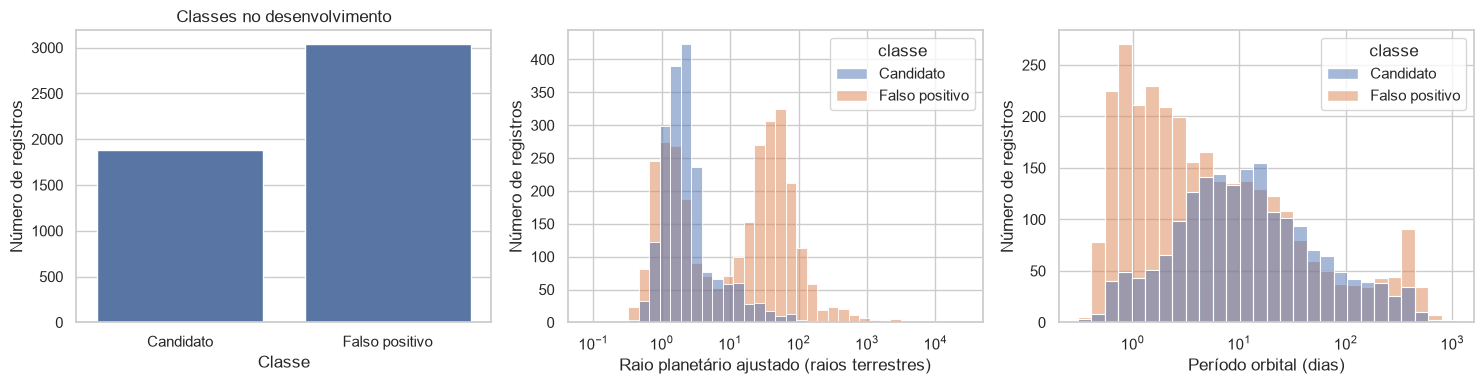

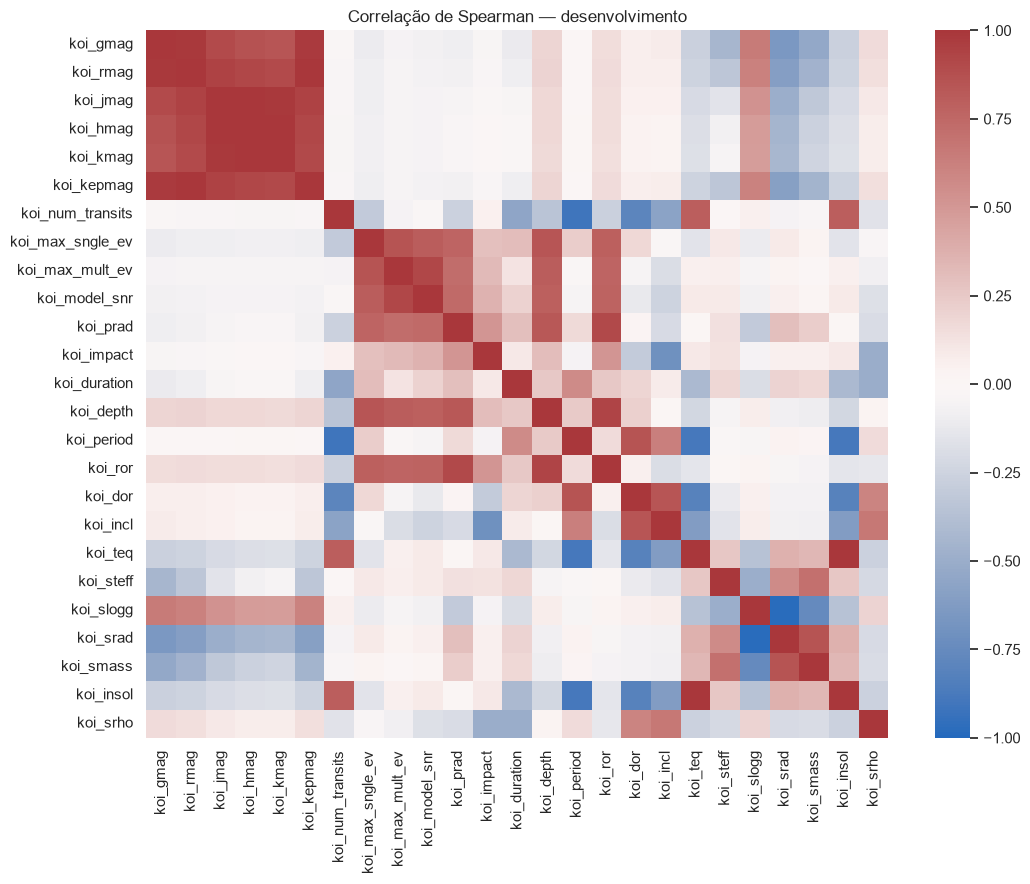

In [11]:
display(X_dev.describe().T)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(
    x=pd.Series(y_dev).map({0: "Falso positivo", 1: "Candidato"}), ax=ax[0]
)
explora = X_dev.assign(
    classe=np.where(y_dev == 1, "Candidato", "Falso positivo")
)
for a, col in zip(ax[1:], ["koi_prad", "koi_period"]):
    sns.histplot(
        data=explora.loc[explora[col] > 0],
        x=col,
        hue="classe",
        log_scale=True,
        ax=a,
    )
ax[0].set(
    title="Classes no desenvolvimento",
    xlabel="Classe",
    ylabel="Número de registros",
)
ax[1].set(
    xlabel="Raio planetário ajustado (raios terrestres)",
    ylabel="Número de registros",
)
ax[2].set(xlabel="Período orbital (dias)", ylabel="Número de registros")
plt.tight_layout()
plt.show()
plt.figure(figsize=(11, 9))
sns.heatmap(
    X_dev.corr(method="spearman"), cmap="vlag", center=0, vmin=-1, vmax=1
)
plt.title("Correlação de Spearman — desenvolvimento")
plt.tight_layout()
plt.show()


## 7. Métricas, padronização e política de decisão

Para candidatos, precisão = TP/(TP+FP), recall = TP/(TP+FN) e F1 é a média harmônica de precisão e recall. F1 macro é a média dos F1 das duas classes; não é acurácia. Também são apresentadas as métricas balanced accuracy, ROC AUC e average precision (AP). AP resume a curva precisão–recall por incrementos de recall e não é a área trapezoidal dessa curva [16,17].

A política principal permanece **maximizar F1 macro**, pois não foi fornecido custo operacional dos erros. Após a seleção dos hiperparâmetros por F1 a 0,5, previsões internas fora da amostra (OOF) são utilizadas para selecionar um limiar na grade predefinida; empates entre escores de limiares favorecem o limiar mais próximo de 0,5. A decisão é `probabilidade > limiar`; igualdade permanece na classe 0, coerente com `predict` a 0,5. A seleção do limiar também é avaliada no fold externo [18].

In [12]:
def metricas(y_, pred, prob):
    return {
        "f1_macro": f1_score(y_, pred, average="macro", zero_division=0),
        "precisao_candidato": precision_score(y_, pred, zero_division=0),
        "recall_candidato": recall_score(y_, pred, zero_division=0),
        "f1_candidato": f1_score(y_, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_, pred),
        "roc_auc": roc_auc_score(y_, prob),
        "average_precision": average_precision_score(y_, prob),
    }


### Escolhendo o limiar

Os limiares são comparados usando apenas previsões internas fora da amostra.

A função recebe os rótulos verdadeiros e os escores OOF. Para cada valor da grade, transforma os escores em classes e calcula as métricas correspondentes. A ordenação prioriza o maior F1 macro; em caso de empate, favorece a menor distância até 0,5 e, persistindo o empate, o menor limiar. O retorno inclui o limiar escolhido e a tabela completa, permitindo examinar a relação entre precisão e recall.

In [13]:
def escolher_limiar(y_, prob):
    tabela = pd.DataFrame(
        [
            {"limiar": float(t), **metricas(y_, (prob > t).astype(int), prob)}
            for t in GRADE_LIMIAR
        ]
    )
    tabela["distancia_05"] = abs(tabela.limiar - 0.5)
    ordenada = tabela.sort_values(
        ["f1_macro", "distancia_05", "limiar"], ascending=[False, True, True]
    )
    return float(ordenada.iloc[0].limiar), tabela


## 8. Como funcionam os modelos e seus espaços de busca

**Baseline.** Dummy sempre prevê a classe mais frequente; serve como referência, sem explorar os atributos [11].

**Logística.** Calcula um escore linear e o transforma pela sigmoide, $p=1/(1+e^{-z})$. A regularização L2 restringe os coeficientes; `C` menor implica penalização maior. O scaler calcula $z=(x-\mu)/\sigma$ no treino de cada fold, sem forçar normalidade [10,12]. Busca: `C` de $10^{-4}$ a 10 e peso de classe nenhum/balanceado; 4.000 iterações são um teto de convergência.

**k-NN.** Vota entre vizinhos no espaço transformado. Distância Manhattan soma diferenças absolutas; euclidiana é a raiz da soma dos quadrados das diferenças. Nos pesos por distância, vizinhos próximos influenciam mais a previsão. `k` varia de 7 a 61, pesos uniforme/distância e distância Manhattan/euclidiana. O parâmetro `p` é restrito a 1 ou 2 por interpretação e custo; a faixa contínua original não é utilizada. `k` maior pode suavizar a fronteira [13].

**PCA.** Combina linearmente os atributos padronizados em direções ortogonais de maior variância. Não usa rótulos para aprender as componentes. O número de componentes (2–25) é escolhido pela validação do classificador. PCA não seleciona colunas e não garante melhor classificação [14]. Com 25 componentes não há redução dimensional; a rotação preserva distâncias euclidianas, mas pode alterar distâncias Manhattan. A variante sem PCA recebe o mesmo orçamento. Também é realizada uma ablação com os mesmos parâmetros de k-NN, alterando apenas a presença do PCA.

**Árvore.** Procura cortes que reduzem Gini ou entropia. Em um nó, $Gini=1-\sum_k p_k^2$ e $H=-\sum_k p_k\log_2(p_k)$, onde $p_k$ é a fração da classe $k$. O corte procura reduzir a impureza ponderada dos nós filhos. Limitar profundidade, tamanho mínimo de folhas e poda por custo-complexidade (`ccp_alpha`) restringe especialização [15].

**Floresta.** Combina árvores treinadas com bootstrap e subconjuntos de atributos por corte. A diversidade procura reduzir variância; o scikit-learn agrega probabilidades. Não há correção sequencial entre árvores [19].

**Boosting.** Soma árvores sequencialmente para reduzir a perda: $F_m=F_{m-1}+\eta h_m$. Os atributos são discretizados em histogramas para procurar cortes com menor custo. Taxa de aprendizado, folhas, profundidade, tamanho mínimo de folha e L2 controlam capacidade [20]. A configuração mantém `early_stopping=False`: o número de etapas é escolhido na CV agrupada, evitando criar silenciosamente uma validação interna por linhas.

| Família | Restrições adicionais da busca |
|---|---|
| Árvore | profundidade 3–12; mínimo para corte 10–40; mínimo por folha 5–40; fração de atributos 0,4–1; poda $10^{-6}$–$10^{-2}$; pesos nenhum/balanceado |
| Floresta | mesmas restrições por árvore; 80, 120, 160 ou 200 árvores; bootstrap ativo |
| Boosting | taxa 0,02–0,12; 80–200 etapas em passos de 40; 7–31 folhas; profundidade 3–8; 20–80 exemplos por folha; L2 0,01–10 |

Esses espaços foram restringidos em relação à versão anterior para incluir modelos menos especializados. O parâmetro `min_samples_leaf` exige suporte mínimo em cada folha; `min_samples_split` exige observações no nó antes da divisão. `max_features` limita os atributos considerados em cada corte, não um subconjunto fixo para toda a floresta.

Regularização reduz o espaço de modelos, mas não garante ausência de sobreajuste. Nenhum espaço abaixo é modificado com base no resultado do holdout.

In [14]:
def sugerir(familia, trial):
    if familia == "Logística":
        return {
            "C": trial.suggest_float("C", 1e-4, 10, log=True),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"]
            ),
        }
    if familia.startswith("k-NN"):
        p = {
            "n_neighbors": trial.suggest_int("n_neighbors", 7, 61),
            "weights": trial.suggest_categorical(
                "weights", ["uniform", "distance"]
            ),
            "p": trial.suggest_categorical("p", [1, 2]),
        }
        if familia == "k-NN + PCA":
            p["componentes"] = trial.suggest_int("componentes", 2, 25)
        return p
    if familia in ["Árvore", "Floresta"]:
        p = {
            "criterion": trial.suggest_categorical(
                "criterion", ["gini", "entropy"]
            ),
            "max_depth": trial.suggest_int("max_depth", 3, 12),
            "min_samples_split": trial.suggest_int(
                "min_samples_split", 10, 40
            ),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 40),
            "max_features": trial.suggest_float("max_features", 0.4, 1.0),
            "ccp_alpha": trial.suggest_float(
                "ccp_alpha", 1e-6, 1e-2, log=True
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"]
            ),
        }
        if familia == "Floresta":
            p["n_estimators"] = trial.suggest_int(
                "n_estimators", 80, 200, step=40
            )
        return p
    if familia == "Boosting":
        return {
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.02, 0.12, log=True
            ),
            "max_iter": trial.suggest_int("max_iter", 80, 200, step=40),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 7, 31),
            "max_depth": trial.suggest_int("max_depth", 3, 8),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 80),
            "l2_regularization": trial.suggest_float(
                "l2_regularization", 0.01, 10, log=True
            ),
        }
    raise ValueError(familia)


### Criando uma instância do modelo

A função `construir` recebe o nome da família e seus hiperparâmetros. Todos os modelos começam com a imputação pela mediana; logística e k-NN acrescentam padronização, e a variante k-NN com PCA inclui a transformação em componentes principais. O classificador ocupa a última etapa. Ao chamar `fit`, cada transformação aprende seus parâmetros exclusivamente com os dados de treino recebidos pelo pipeline.

In [15]:
def construir(familia, parametros):
    p = dict(parametros)
    etapas = [
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True))
    ]
    if familia == "Baseline":
        modelo = DummyClassifier(strategy="most_frequent")
    elif familia == "Logística":
        etapas.append(("scaler", StandardScaler()))
        modelo = LogisticRegression(
            **p, solver="lbfgs", max_iter=4000, random_state=SEMENTE
        )
    elif familia.startswith("k-NN"):
        componentes = p.pop("componentes", None)
        etapas.append(("scaler", StandardScaler()))
        if componentes is not None:
            etapas.append(
                ("pca", PCA(n_components=componentes, svd_solver="full"))
            )
        modelo = KNeighborsClassifier(**p, n_jobs=1)
    elif familia == "Árvore":
        modelo = DecisionTreeClassifier(**p, random_state=SEMENTE)
    elif familia == "Floresta":
        modelo = RandomForestClassifier(
            **p, bootstrap=True, n_jobs=1, random_state=SEMENTE
        )
    elif familia == "Boosting":
        modelo = HistGradientBoostingClassifier(
            **p, early_stopping=False, random_state=SEMENTE
        )
    else:
        raise ValueError(familia)
    return Pipeline(etapas + [("modelo", modelo)])


### Registrando o protocolo

Os arquivos de registro guardam a configuração do experimento, as versões das bibliotecas, a auditoria e a indicação de quais objetos pertencem a cada conjunto. A pasta de saída é identificada pelo hash do protocolo. Como esse protocolo inclui um hash do texto de funções, uma mudança de formatação pode produzir outra pasta mesmo quando os cálculos são equivalentes. Esses registros ajudam a distinguir execuções e a interpretar seus resultados.

In [16]:
import inspect

HASH_IMPLEMENTACAO = hashlib.sha256(
    (inspect.getsource(sugerir) + inspect.getsource(construir)).encode()
).hexdigest()
PROTOCOLO = {
    "revisao": "2026-11-13-v2",
    "hash_dados": HASH_DADOS,
    "hash_modelos": HASH_IMPLEMENTACAO,
    "semente": SEMENTE,
    "externos": N_EXTERNO,
    "internos": N_INTERNO,
    "tentativas": N_TRIALS,
    "grade_limiar": GRADE_LIMIAR.tolist(),
    "versoes": VERSOES,
    "regra": "maior F1 interno a 0.5; depois limiar OOF para F1 macro",
    "origem": "CSV fornecido; data/consulta original desconhecidas",
}
HASH_PROTOCOLO = hashlib.sha256(
    json.dumps(PROTOCOLO, sort_keys=True).encode()
).hexdigest()[:12]
SAIDA = Path("resultados_tiamat") / HASH_PROTOCOLO
SAIDA.mkdir(parents=True, exist_ok=True)
(SAIDA / "protocolo.json").write_text(
    json.dumps(PROTOCOLO, indent=2, ensure_ascii=False)
)
(SAIDA / "requirements.txt").write_text(
    "\n".join(f"{p}=={v}" for p, v in VERSOES.items())
)
auditoria.to_csv(SAIDA / "auditoria.csv", index=False)
particao = dados[[GRUPO, OBJETO, TARGET]].copy()
particao["conjunto"] = "desenvolvimento"
particao.loc[idx_teste, "conjunto"] = "teste"
particao.to_csv(SAIDA / "particao.csv", index=False)


## 9. Optuna e rastreamento da busca

As funções têm nomes próprios e recebem a família explicitamente; a implementação não redefine uma função global diferente para cada algoritmo. O dicionário de parâmetros é copiado antes de retirar `componentes`, preservando o registro original do Optuna.

| Função | O que recebe e devolve |
|---|---|
| `sugerir` | Família e tentativa Optuna; devolve os hiperparâmetros sugeridos |
| `construir` | Família e dicionário; devolve um pipeline novo, ainda não ajustado |
| `buscar` | Dados de treino e folds internos; devolve parâmetros e pontuação da melhor tentativa |
| `ajustar_politica` | Melhor configuração; gera previsões internas OOF, escolhe o limiar e ajusta no treino disponível |
| `metricas` | Rótulos, classes previstas e escores; devolve métricas distintas |
| `folds_grupados` | Atributos, alvo e estrela; devolve índices e verifica isolamento dos grupos |

OOF significa *out-of-fold*: a previsão de uma linha é produzida por um modelo ajustado sem o fold ao qual ela pertence. OOF interno usado para escolher um limiar ainda pertence ao desenvolvimento; seu F1 otimizado não é apresentado como desempenho independente. Embora o ajuste de cada estimador exclua o respectivo fold, os rótulos internos já participaram da escolha dos hiperparâmetros. A avaliação externa é que mede essa sequência completa de decisões.

O TPE usa o histórico das tentativas para propor valores promissores [21]. `log=True` modifica a distribuição de amostragem do hiperparâmetro, não os atributos. Cada avaliação interna ajusta um pipeline novo; imputação, scaler e PCA não observam o fold de validação [6].

A busca utiliza os mesmos folds para todas as famílias dentro de cada partição externa. São salvos estudos SQLite, a tabela completa de tentativas, os parâmetros vencedores e as contagens de tentativas completas, falhas e configurações únicas. A versão entregue registra também uma assinatura das entradas, colunas, rótulos e índices dos folds em cada estudo; mudanças incompatíveis interrompem a reutilização. Alterações nas regras metodológicas exigem a atualização da identificação de revisão no protocolo. Um checkpoint só é reutilizado quando o protocolo é compatível; os estudos usam sementes específicas e não repetem tentativas já completas. Uma retomada com novas tentativas não garante a mesma sequência de TPE de uma execução ininterrupta.

In [17]:
def buscar(familia, X_, y_, folds, nome, seed):
    t0 = time.perf_counter()
    estudo = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=seed),
        storage=f"sqlite:///{(SAIDA/'estudos.sqlite3').resolve()}",
        study_name=nome,
        load_if_exists=True,
    )
    assinatura = hashlib.sha256()
    assinatura.update(
        pd.util.hash_pandas_object(X_, index=False).to_numpy().tobytes()
    )
    assinatura.update(json.dumps(list(X_.columns)).encode())
    assinatura.update(np.asarray(y_, dtype=np.int64).tobytes())
    assinatura.update(
        json.dumps([(a.tolist(), b.tolist()) for a, b in folds]).encode()
    )
    assinatura = assinatura.hexdigest()
    anterior = estudo.user_attrs.get("assinatura_entradas")
    if anterior is not None and anterior != assinatura:
        raise ValueError(
            "Checkpoint incompatível com dados, atributos, rótulos ou folds. Use nova revisão."
        )
    estudo.set_user_attr("assinatura_entradas", assinatura)
    estudo.set_user_attr("atributos", list(X_.columns))

    def objetivo(trial):
        parametros = sugerir(familia, trial)
        estimador = construir(familia, parametros)
        with parallel_backend("loky", inner_max_num_threads=1):
            valores = cross_val_score(
                estimador,
                X_,
                y_,
                cv=folds,
                scoring="f1_macro",
                n_jobs=N_JOBS,
                error_score="raise",
            )
        trial.set_user_attr("f1_folds", [float(v) for v in valores])
        trial.set_user_attr("desvio_folds", float(np.std(valores, ddof=1)))
        return float(np.mean(valores))

    restantes = max(0, N_TRIALS - len(estudo.trials))
    estudo.optimize(objetivo, n_trials=restantes)
    tabela = estudo.trials_dataframe()
    tabela.to_csv(SAIDA / f"{nome}_tentativas.csv", index=False)
    completas = [t for t in estudo.trials if t.state == TrialState.COMPLETE]
    if len(completas) != N_TRIALS:
        raise RuntimeError(f"{nome}: tentativas incompletas")
    unicas = len({json.dumps(t.params, sort_keys=True) for t in completas})
    info = {
        "estudo": nome,
        "familia": familia,
        "tentativas": len(estudo.trials),
        "completas": len(completas),
        "falhas": sum(t.state == TrialState.FAIL for t in estudo.trials),
        "configuracoes_unicas": unicas,
        "melhor_f1_interno": estudo.best_value,
        "parametros": estudo.best_params,
        "segundos_nesta_chamada": time.perf_counter() - t0,
        "tentativas_novas": restantes,
        "segundos_tentativas": sum(
            (t.datetime_complete - t.datetime_start).total_seconds()
            for t in completas
        ),
    }
    (SAIDA / f"{nome}_melhor.json").write_text(
        json.dumps(info, indent=2, ensure_ascii=False)
    )
    with (SAIDA / "progresso.log").open("a") as f:
        f.write(
            f'{nome}: CV interna={estudo.best_value:.4f}; {unicas} únicas; {info["segundos_tentativas"]:.1f}s\n'
        )
    print(
        nome,
        "| F1 interno:",
        round(estudo.best_value, 4),
        "| únicas:",
        unicas,
        flush=True,
    )
    return info


### Treinando com a configuração escolhida

Após a busca, são produzidas previsões OOF para a seleção do limiar, seguida do ajuste do modelo no treino disponível.

A função `ajustar_politica` constrói um novo pipeline com os hiperparâmetros vencedores. Primeiro, `cross_val_predict` calcula um escore para cada observação usando um ajuste que exclui seu fold. Esses escores orientam a escolha do limiar. Depois, o pipeline é ajustado em todo o treino disponível nessa chamada. O retorno reúne modelo treinado, limiar e tabela de cenários, mantendo a regra de classificação associada ao estimador.

In [18]:
def ajustar_politica(familia, info, X_, y_, folds):
    estimador = construir(familia, info["parametros"])
    with parallel_backend("loky", inner_max_num_threads=1):
        prob_oof = cross_val_predict(
            estimador, X_, y_, cv=folds, method="predict_proba", n_jobs=N_JOBS
        )[:, 1]
    limiar, tab = escolher_limiar(y_, prob_oof)
    with threadpool_limits(limits=1):
        estimador.fit(X_, y_)
    return estimador, limiar, tab


## 10. Avaliação externa: cada família e o procedimento de seleção

Cada observação do desenvolvimento recebe uma previsão de um modelo que não usou sua estrela no treinamento nem na otimização. São registradas métricas com limiar 0,5 e com o limiar escolhido internamente. O F1 de treino é apenas diagnóstico de ajuste; não é evidência de generalização.

A linha `Seleção automática` de cada fold avalia a família escolhida **pela CV interna**, não pelo melhor resultado daquele fold externo. Isso inclui na avaliação a etapa de escolher o algoritmo [9].

In [19]:
registros = []
ablac = []
historico_buscas = []
previsoes_externas = []


### Treinando e avaliando nos folds externos

Em cada repetição, a busca usa somente o treino externo. O baseline e as famílias são avaliados na mesma validação.

O laço separa os índices de treino e validação de cada fold. Dentro do treino, novas divisões agrupadas orientam a busca de hiperparâmetros e a escolha do limiar. Só então o modelo prevê os rótulos da validação externa. Além das métricas por família, o código registra as previsões individuais e a ablação do PCA. A família escolhida automaticamente é definida pelo desempenho interno, antes de considerar sua pontuação externa.

In [20]:
for fold, (tr, va) in enumerate(externos, 1):
    Xt, Xv = X_dev.iloc[tr], X_dev.iloc[va]
    yt, yv = y_dev[tr], y_dev[va]
    internos = folds_grupados(
        Xt, yt, g_dev[tr], N_INTERNO, SEMENTE + 100 + fold
    )
    resultados_fold = []
    base = construir("Baseline", {})
    base.fit(Xt, yt)
    pb = base.predict_proba(Xv)[:, 1]
    registros.append(
        {
            "fold": fold,
            "familia": "Baseline",
            "limiar": 0.5,
            "f1_treino": f1_score(yt, base.predict(Xt), average="macro"),
            "f1_externo_05": f1_score(yv, base.predict(Xv), average="macro"),
            **metricas(yv, base.predict(Xv), pb),
        }
    )
    for j, familia in enumerate(FAMILIAS):
        info = buscar(
            familia,
            Xt,
            yt,
            internos,
            f"externo_{fold}_familia_{j}",
            SEMENTE + fold * 100 + j,
        )
        historico_buscas.append(info)
        modelo, t, tab = ajustar_politica(familia, info, Xt, yt, internos)
        prob = modelo.predict_proba(Xv)[:, 1]
        pred = (prob > t).astype(int)
        ftrain = f1_score(
            yt,
            (modelo.predict_proba(Xt)[:, 1] > t).astype(int),
            average="macro",
        )
        linha = {
            "fold": fold,
            "familia": familia,
            "limiar": t,
            "f1_treino": ftrain,
            "f1_externo_05": f1_score(
                yv, (prob > 0.5).astype(int), average="macro"
            ),
            "f1_interno_selecao": info["melhor_f1_interno"],
            **metricas(yv, pred, prob),
        }
        registros.append(linha)
        resultados_fold.append((info, linha, prob, pred))
        previsoes_externas.append(
            pd.DataFrame(
                {
                    "pos_dev": va,
                    "fold": fold,
                    "familia": familia,
                    "y": yv,
                    "prob": prob,
                    "pred": pred,
                    "limiar": t,
                }
            )
        )
        if familia == "k-NN + PCA":
            # Ablação controlada: mesmos k, p, pesos, dados, imputação e scaler; só removemos PCA.
            params = dict(info["parametros"])
            params.pop("componentes")
            sem = construir("k-NN sem PCA", params)
            sem.fit(Xt, yt)
            psem = sem.predict_proba(Xv)[:, 1]
            fsem = f1_score(yv, (psem > 0.5).astype(int), average="macro")
            ablac.append(
                {
                    "fold": fold,
                    "componentes": info["parametros"]["componentes"],
                    "variancia_retida": float(
                        modelo.named_steps[
                            "pca"
                        ].explained_variance_ratio_.sum()
                    ),
                    "f1_com_pca": linha["f1_externo_05"],
                    "f1_sem_pca_mesmos_parametros": fsem,
                    "diferenca": linha["f1_externo_05"] - fsem,
                }
            )
    escolhido = max(resultados_fold, key=lambda r: r[0]["melhor_f1_interno"])
    registros.append(
        {
            **escolhido[1],
            "familia": "Seleção automática",
            "familia_escolhida": escolhido[0]["familia"],
        }
    )
    pd.DataFrame(registros).to_csv(
        SAIDA / "metricas_externas.csv", index=False
    )
    pd.DataFrame(ablac).to_csv(SAIDA / "ablacao_pca.csv", index=False)
    pd.concat(previsoes_externas).to_csv(
        SAIDA / "previsoes_externas.csv", index=False
    )


externo_1_familia_0 | F1 interno: 0.8062 | únicas: 100
externo_1_familia_1 | F1 interno: 0.7963 | únicas: 64
externo_1_familia_2 | F1 interno: 0.7965 | únicas: 99
externo_1_familia_3 | F1 interno: 0.8105 | únicas: 100
externo_1_familia_4 | F1 interno: 0.8343 | únicas: 100
externo_1_familia_5 | F1 interno: 0.8479 | únicas: 100
externo_2_familia_0 | F1 interno: 0.8004 | únicas: 100
externo_2_familia_1 | F1 interno: 0.7868 | únicas: 59
externo_2_familia_2 | F1 interno: 0.792 | únicas: 96
externo_2_familia_3 | F1 interno: 0.8004 | únicas: 100
externo_2_familia_4 | F1 interno: 0.8258 | únicas: 100
externo_2_familia_5 | F1 interno: 0.8426 | únicas: 100
externo_3_familia_0 | F1 interno: 0.8081 | únicas: 100
externo_3_familia_1 | F1 interno: 0.7927 | únicas: 74
externo_3_familia_2 | F1 interno: 0.7968 | únicas: 99
externo_3_familia_3 | F1 interno: 0.8055 | únicas: 100
externo_3_familia_4 | F1 interno: 0.8337 | únicas: 100
externo_3_familia_5 | F1 interno: 0.8421 | únicas: 100
externo_4_familia

### Organizando os resultados

As métricas são reunidas para o cálculo da média e da dispersão entre folds. As saídas deste bloco incluem o progresso das buscas anteriores.

A tabela `externa` guarda uma linha por família e fold; `resumo` agrega essas linhas. `f1_medio` descreve o desempenho médio, `f1_dp` mostra a variação entre folds e `gap_treino_validacao` compara as médias de treino e validação. Valores altos no treino acompanhados de desempenho externo menor sugerem examinar a capacidade de generalização. A ordenação da tabela facilita a leitura, mas não substitui a regra de seleção interna adotada no experimento.

In [21]:
externa = pd.DataFrame(registros)
ablacao = pd.DataFrame(ablac)
resumo = externa.groupby("familia").agg(
    f1_medio=("f1_macro", "mean"),
    f1_dp=("f1_macro", "std"),
    treino_medio=("f1_treino", "mean"),
    recall_medio=("recall_candidato", "mean"),
    precisao_media=("precisao_candidato", "mean"),
    ap_media=("average_precision", "mean"),
)
resumo["gap_treino_validacao"] = resumo.treino_medio - resumo.f1_medio
resumo = resumo.sort_values("f1_medio", ascending=False)
display(resumo.round(4))
display(externa.round(4))


,f1_medio,f1_dp,treino_medio,recall_medio,precisao_media,ap_media,gap_treino_validacao
familia,,,,,,,
Boosting,0.8459,0.0034,0.9480,0.8193,0.8028,0.8801,0.1021
Seleção automática,0.8459,0.0034,0.9480,0.8193,0.8028,0.8801,0.1021
Floresta,0.8340,0.0104,0.9054,0.8119,0.7839,0.8665,0.0714
Árvore,0.8035,0.0089,0.8420,0.7725,0.7487,0.7777,0.0385
k-NN + PCA,0.8019,0.0172,0.9631,0.7949,0.7329,0.7852,0.1612
Logística,0.8007,0.0126,0.8086,0.7912,0.7323,0.7730,0.0079
k-NN sem PCA,0.7931,0.0116,1.0000,0.8023,0.7126,0.7853,0.2069
Baseline,0.3817,0.0002,0.3817,0.0000,0.0000,0.3827,0.0000


,fold,familia,limiar,f1_treino,f1_externo_05,f1_macro,precisao_candidato,recall_candidato,f1_candidato,balanced_accuracy,roc_auc,average_precision,f1_interno_selecao,familia_escolhida
0,1,Baseline,0.500,0.3816,0.3819,0.3819,0.0000,0.0000,0.0000,0.5000,0.5000,0.3821,NaN,NaN
1,1,Logística,0.550,0.8080,0.7948,0.7930,0.7473,0.7394,0.7433,0.7924,0.8737,0.7897,0.8062,NaN
2,1,k-NN sem PCA,0.500,1.0000,0.7814,0.7814,0.7026,0.7793,0.7390,0.7877,0.8642,0.7782,0.7963,NaN
3,1,k-NN + PCA,0.500,1.0000,0.7814,0.7814,0.7026,0.7793,0.7390,0.7877,0.8642,0.7784,0.7965,NaN
4,1,Árvore,0.500,0.8351,0.7923,0.7923,0.7358,0.7553,0.7454,0.7938,0.8693,0.7835,0.8105,NaN
5,1,Floresta,0.525,0.9004,0.8232,0.8210,0.7922,0.7606,0.7761,0.8186,0.9105,0.8621,0.8343,NaN
6,1,Boosting,0.500,0.9417,0.8472,0.8472,0.8112,0.8112,0.8112,0.8472,0.9227,0.8824,0.8479,NaN
7,1,Seleção automática,0.500,0.9417,0.8472,0.8472,0.8112,0.8112,0.8112,0.8472,0.9227,0.8824,0.8479,Boosting
8,2,Baseline,0.500,0.3817,0.3815,0.3815,0.0000,0.0000,0.0000,0.5000,0.5000,0.3831,NaN,NaN
9,2,Logística,0.500,0.8050,0.8186,0.8186,0.7446,0.8276,0.7839,0.8257,0.8930,0.7855,0.8004,NaN


## 11. Dispersão, comparação pareada e ablação do PCA

Os pontos são resultados de folds externos; as barras de erro abaixo são **desvios-padrão**, não intervalos de confiança. Os folds compartilham dados de treinamento, portanto os cinco escores não são tratados como cinco experimentos independentes para um teste t simples [25].

Boosting e floresta são comparados nos mesmos folds, com apresentação das diferenças pareadas, sem declaração de superioridade universal. Para o PCA há duas perguntas: (a) qual pipeline otimizado funciona melhor, com orçamento igual? (b) com os parâmetros do k-NN com PCA mantidos, o que acontece ao remover o PCA? A segunda é uma ablação controlada, mas está condicionada aos parâmetros escolhidos para a versão com PCA e pode favorecê-la. A soma de `explained_variance_ratio_` informa a variância preservada, não a informação de classe preservada [14].

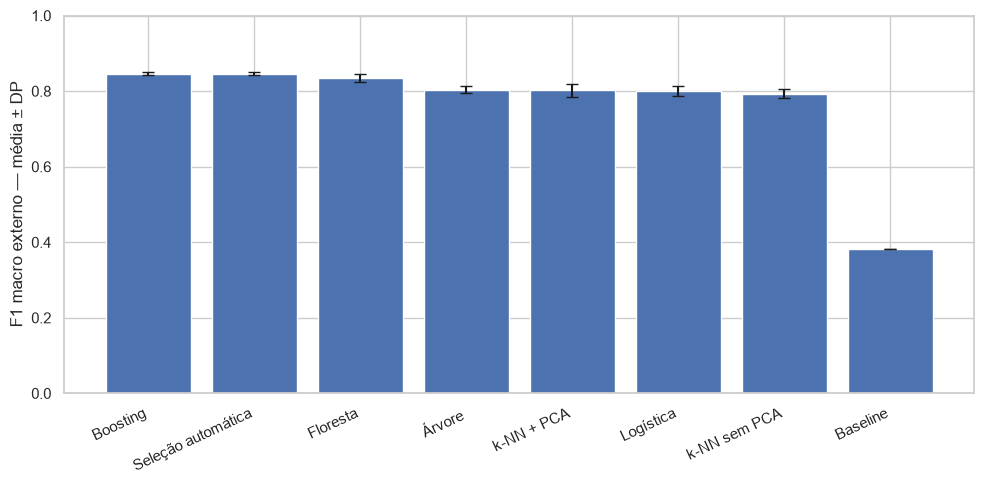

,Boosting,Floresta,diferença_pareada
fold,,,
1,0.8472,0.8210,0.0262
2,0.8512,0.8494,0.0019
3,0.8430,0.8294,0.0136
4,0.8446,0.8365,0.0081
5,0.8434,0.8339,0.0095


,fold,componentes,variancia_retida,f1_com_pca,f1_sem_pca_mesmos_parametros,diferenca
0,1,24,0.9999,0.7814,0.7814,0.0000
1,2,22,0.9997,0.8281,0.8133,0.0147
2,3,22,0.9996,0.8033,0.8019,0.0014
3,4,23,0.9999,0.7941,0.7802,0.0139
4,5,22,0.9996,0.7954,0.7916,0.0038


Diferença média da ablação (com - sem PCA): 0.0068


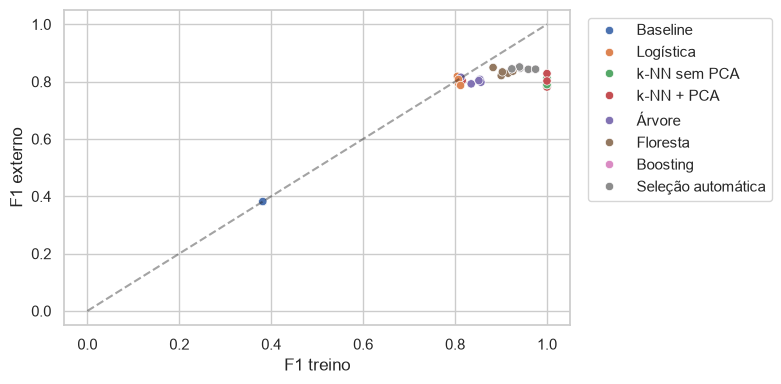

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(resumo.index, resumo.f1_medio, yerr=resumo.f1_dp, capsize=4)
ax.set(ylabel="F1 macro externo — média ± DP", ylim=(0, 1))
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
pivot = externa.pivot(index="fold", columns="familia", values="f1_macro")
comparacao = pd.DataFrame(
    {"Boosting": pivot["Boosting"], "Floresta": pivot["Floresta"]}
)
comparacao["diferença_pareada"] = comparacao.Boosting - comparacao.Floresta
display(comparacao.round(4))
display(ablacao.round(4))
print(
    "Diferença média da ablação (com - sem PCA):",
    round(ablacao.diferenca.mean(), 4),
)
plt.figure(figsize=(8, 4))
sns.scatterplot(data=externa, x="f1_treino", y="f1_macro", hue="familia")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("F1 treino")
plt.ylabel("F1 externo")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 12. Ajuste final e congelamento da decisão antes do teste

A busca de cada família é repetida sobre todo o desenvolvimento, com três folds internos agrupados e o mesmo orçamento. A seleção utiliza a maior média interna a 0,5, como no procedimento externo. Em seguida, o limiar é selecionado por OOF interno. A função `cross_val_predict(..., method="predict_proba")` devolve os escores na ordem original das linhas; `[:, 1]` seleciona a coluna da classe candidato, pois o alvo foi codificado como 0/1. O procedimento não calcula médias de rótulos nem mistura índices de folds. O modelo, os parâmetros, o limiar, o hash e a política são salvos **antes** do cálculo das métricas no holdout.

As curvas de aprendizado seguintes usam somente desenvolvimento e parâmetros já selecionados nele. São diagnósticos condicionados à configuração; não substituem a estimativa externa aninhada [22]. As curvas não são utilizadas para modificar novamente o modelo nesta execução.

In [23]:
folds_final = folds_grupados(X_dev, y_dev, g_dev, N_INTERNO, SEMENTE + 900)
buscas_finais = []
for j, familia in enumerate(FAMILIAS):
    info = buscar(
        familia,
        X_dev,
        y_dev,
        folds_final,
        f"final_familia_{j}",
        SEMENTE + 900 + j,
    )
    buscas_finais.append(info)
    historico_buscas.append(info)


final_familia_0 | F1 interno: 0.8047 | únicas: 100
final_familia_1 | F1 interno: 0.7966 | únicas: 58
final_familia_2 | F1 interno: 0.8012 | únicas: 92
final_familia_3 | F1 interno: 0.805 | únicas: 100
final_familia_4 | F1 interno: 0.8354 | únicas: 100
final_familia_5 | F1 interno: 0.8498 | únicas: 100


### Escolhendo o modelo final

A melhor média interna determina a família; o teste permanece reservado.

As melhores pontuações das buscas realizadas em todo o desenvolvimento são comparadas. A configuração vencedora passa pela função de ajuste da política, que seleciona o limiar a partir de previsões OOF e treina o pipeline final. O modelo e a política são salvos antes de calcular as métricas de teste. Assim, parâmetros, família e limiar já estão definidos quando o conjunto reservado é avaliado.

In [24]:
vencedor = max(buscas_finais, key=lambda r: r["melhor_f1_interno"])
familia_final = vencedor["familia"]
modelo_final, limiar_final, cenarios = ajustar_politica(
    familia_final, vencedor, X_dev, y_dev, folds_final
)
politica = {
    "familia": familia_final,
    "parametros": vencedor["parametros"],
    "limiar": limiar_final,
    "criterio": "F1 macro interno a 0.5 para família/hiperparâmetros; F1 macro OOF para limiar",
    "hash_dados": HASH_DADOS,
    "hash_protocolo": HASH_PROTOCOLO,
}
(SAIDA / "politica_congelada.json").write_text(
    json.dumps(politica, indent=2, ensure_ascii=False)
)
dump(
    {"modelo": modelo_final, "politica": politica, "atributos": ATRIBUTOS},
    SAIDA / "modelo_final.joblib",
)


['resultados_tiamat\\126d5f8ed9a5\\modelo_final.joblib']

### Resultados da seleção final

São apresentados a família selecionada, os parâmetros e os cenários de limiar. O progresso das buscas também está preservado abaixo.

A primeira tabela permite comparar o melhor F1 interno e os hiperparâmetros encontrados para cada família. A tabela de cenários mostra como precisão, recall e F1 macro variam com o limiar. O cenário de recall de pelo menos 90% é apresentado apenas para discussão: ele não altera a política principal. Quando o modelo final contém PCA, também é informada a proporção de variância retida pelas componentes.

In [25]:
print("Família escolhida:", familia_final, "| limiar:", limiar_final)
display(
    pd.DataFrame(buscas_finais)[
        ["familia", "melhor_f1_interno", "configuracoes_unicas", "parametros"]
    ]
)
display(
    cenarios[
        ["limiar", "f1_macro", "precisao_candidato", "recall_candidato"]
    ].round(4)
)
viaveis = cenarios[cenarios.recall_candidato >= 0.9]
if len(viaveis):
    print(
        "Cenário exploratório de recall OOF ≥ 90%; NÃO adotado como política principal:"
    )
    display(
        viaveis.sort_values(
            ["precisao_candidato", "limiar"], ascending=False
        ).head(1)
    )
else:
    print("A grade avaliada não atingiu recall OOF de 90%.")
if "pca" in modelo_final.named_steps:
    print(
        "Variância retida pelo PCA final:",
        modelo_final.named_steps["pca"].explained_variance_ratio_.sum(),
    )


Família escolhida: Boosting | limiar: 0.5


,familia,melhor_f1_interno,configuracoes_unicas,parametros
0,Logística,0.804677,100,"{'C': 6.982027596959528, 'class_weight': None}"
1,k-NN sem PCA,0.796559,58,"{'n_neighbors': 10, 'weights': 'uniform', 'p': 2}"
2,k-NN + PCA,0.801215,92,"{'n_neighbors': 14, 'weights': 'uniform', 'p': 1, 'componentes': 22}"
3,Árvore,0.804982,100,"{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 14, 'min_samples_leaf': 23, 'max_features': 0.6410577907895946, 'ccp_alpha': 0.0012016687644144405, 'class_weight': None}"
4,Floresta,0.835412,100,"{'criterion': 'entropy', 'max_depth': 12, 'min_samples_split': 10, 'min_samples_leaf': 6, 'max_features': 0.5989041091027864, 'ccp_alpha': 1.6692561362924654e-06, 'class_weight': None, 'n_estimators': 160}"
5,Boosting,0.849780,100,"{'learning_rate': 0.08381906724179523, 'max_iter': 200, 'max_leaf_nodes': 28, 'max_depth': 8, 'min_samples_leaf': 31, 'l2_regularization': 0.02556645816042427}"


,limiar,f1_macro,precisao_candidato,recall_candidato
0,0.100,0.7813,0.6491,0.9378
1,0.125,0.7939,0.6674,0.9277
2,0.150,0.8024,0.6811,0.9192
3,0.175,0.8074,0.6915,0.9086
4,0.200,0.8140,0.7054,0.8969
5,0.225,0.8184,0.7139,0.8921
6,0.250,0.8218,0.7223,0.8847
7,0.275,0.8262,0.7328,0.8773
8,0.300,0.8276,0.7389,0.8693
9,0.325,0.8323,0.7497,0.8640


Cenário exploratório de recall OOF ≥ 90%; NÃO adotado como política principal:


,limiar,f1_macro,precisao_candidato,recall_candidato,f1_candidato,balanced_accuracy,roc_auc,average_precision,distancia_05
3,0.175,0.807357,0.691468,0.908608,0.785304,0.828645,0.919889,0.877252,0.325


In [26]:
curvas = []
for fold, (tr, va) in enumerate(externos, 1):
    rng = np.random.default_rng(SEMENTE + fold)
    estrelas = np.unique(g_dev[tr])
    rng.shuffle(estrelas)
    for fracao in [0.25, 0.5, 1.0]:
        escolhidas = estrelas[: max(2, int(len(estrelas) * fracao))]
        sub = tr[np.isin(g_dev[tr], escolhidas)]
        if len(np.unique(y_dev[sub])) < 2:
            continue
        m = construir(familia_final, vencedor["parametros"])
        m.fit(X_dev.iloc[sub], y_dev[sub])
        curvas.append(
            {
                "fold": fold,
                "fracao": fracao,
                "n": len(sub),
                "treino": f1_score(
                    y_dev[sub], m.predict(X_dev.iloc[sub]), average="macro"
                ),
                "validacao": f1_score(
                    y_dev[va], m.predict(X_dev.iloc[va]), average="macro"
                ),
            }
        )


### Visualizando a curva de aprendizado

As pontuações de treino e validação são comparadas para diferentes quantidades de dados.

A tabela `curvas` registra, para cada fold e fração de treino, o número de exemplos e as duas pontuações. Em seguida, as médias são agrupadas por fração para construir o gráfico. A interpretação considera tanto a distância entre as curvas quanto a evolução do desempenho de validação conforme mais exemplos são utilizados. Os hiperparâmetros permanecem fixos nesta análise; por isso, ela é um diagnóstico da configuração escolhida, e não uma nova busca de modelos.

,fold,fracao,n,treino,validacao
0,1,0.25,983,1.000000,0.832469
1,1,0.50,1967,1.000000,0.834617
2,1,1.00,3934,0.992218,0.848724
3,2,0.25,983,1.000000,0.829831
4,2,0.50,1967,1.000000,0.837919
5,2,1.00,3934,0.990332,0.858795
6,3,0.25,983,1.000000,0.816210
7,3,0.50,1967,1.000000,0.838424
8,3,1.00,3934,0.994095,0.850947
9,4,0.25,983,1.000000,0.827906


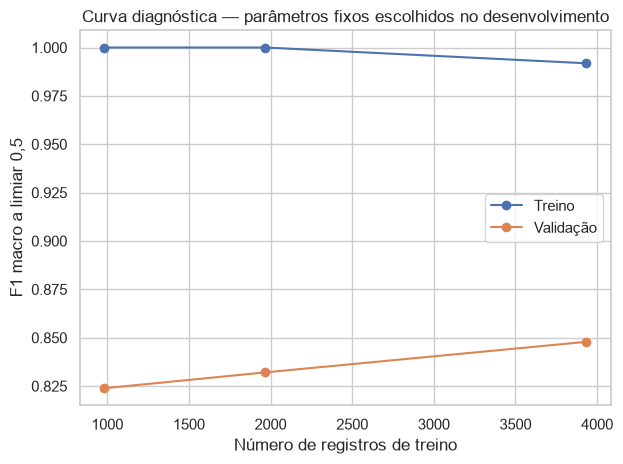

In [27]:
curvas = pd.DataFrame(curvas)
display(curvas)
agg = curvas.groupby("fracao").agg(
    n=("n", "mean"), treino=("treino", "mean"), validacao=("validacao", "mean")
)
plt.plot(agg.n, agg.treino, "o-", label="Treino")
plt.plot(agg.n, agg.validacao, "o-", label="Validação")
plt.xlabel("Número de registros de treino")
plt.ylabel("F1 macro a limiar 0,5")
plt.title("Curva diagnóstica — parâmetros fixos escolhidos no desenvolvimento")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Avaliação final e incerteza por bootstrap de estrelas

A partir daqui o holdout é aberto apenas para avaliação. São apresentados os resultados das duas classes, a matriz de confusão, as curvas PR e o desempenho com os limiares padrão e congelado. Nenhuma dessas medidas altera a decisão.

O bootstrap sorteia estrelas com reposição e inclui todos os objetos de cada estrela sorteada. Os percentis 2,5 e 97,5 formam um intervalo aproximado de 95%. O agrupamento preserva a dependência interna quando há múltiplos objetos por estrela. Neste recorte, com uma linha por estrela, equivale a reamostrar linhas [23].

**Limites:** os intervalos são condicionais ao modelo já ajustado e ao holdout disponível; não incluem toda a incerteza de refazer treino/busca, erros dos rótulos, mudanças entre missões ou histórico de exploração. O bootstrap não transforma o conjunto em teste externo. Pequenos subgrupos são mostrados apenas como diagnóstico.

,f1_macro,precisao_candidato,recall_candidato,f1_candidato,balanced_accuracy,roc_auc,average_precision
"limiar 0,5",0.8801,0.8441,0.862,0.8529,0.8816,0.9478,0.917
limiar congelado,0.8801,0.8441,0.862,0.8529,0.8816,0.9478,0.917


,precision,recall,f1-score,support
Falso positivo,0.9132,0.9012,0.9072,759.0000
Candidato,0.8441,0.8620,0.8529,471.0000
accuracy,0.8862,0.8862,0.8862,0.8862
macro avg,0.8786,0.8816,0.8801,1230.0000
weighted avg,0.8867,0.8862,0.8864,1230.0000


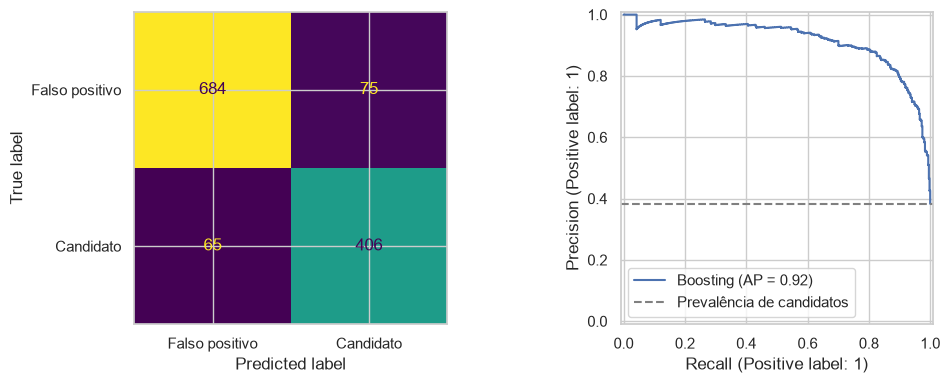

Réplicas válidas: 1000 de 1000


,estimativa,IC95_inferior,IC95_superior
f1_macro,0.8801,0.8608,0.8979
precisao_candidato,0.8441,0.8103,0.8758
recall_candidato,0.8620,0.8296,0.8911
f1_candidato,0.8529,0.8264,0.8761
balanced_accuracy,0.8816,0.8621,0.8996
roc_auc,0.9478,0.9344,0.9587
average_precision,0.9170,0.8925,0.9394


,subgrupo,n,f1_macro,precisao_candidato,recall_candidato,f1_candidato,balanced_accuracy,roc_auc,average_precision
0,completos,1213,0.8806,0.8476,0.862,0.8547,0.8818,0.9477,0.918


In [28]:
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste > limiar_final).astype(int)
resultado_teste = metricas(y_teste, pred_teste, prob_teste)
resultado_05 = metricas(y_teste, (prob_teste > 0.5).astype(int), prob_teste)
display(
    pd.DataFrame(
        [resultado_05, resultado_teste],
        index=["limiar 0,5", "limiar congelado"],
    ).round(4)
)
relatorio = pd.DataFrame(
    classification_report(
        y_teste,
        pred_teste,
        target_names=["Falso positivo", "Candidato"],
        output_dict=True,
        zero_division=0,
    )
).T
display(relatorio.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    pred_teste,
    display_labels=["Falso positivo", "Candidato"],
    ax=ax[0],
    colorbar=False,
)
PrecisionRecallDisplay.from_predictions(
    y_teste, prob_teste, ax=ax[1], name=familia_final
)
ax[1].axhline(
    y_teste.mean(), ls="--", color="gray", label="Prevalência de candidatos"
)
ax[1].legend()
plt.tight_layout()
plt.show()

rng = np.random.default_rng(SEMENTE + 5000)
estrelas = np.unique(g_teste)
indices_estrelas = [np.flatnonzero(g_teste == e) for e in estrelas]
boot = []
for _ in range(N_BOOTSTRAP):
    sorteadas = rng.integers(0, len(estrelas), len(estrelas))
    ix = np.concatenate([indices_estrelas[k] for k in sorteadas])
    if len(np.unique(y_teste[ix])) < 2:
        continue
    boot.append(metricas(y_teste[ix], pred_teste[ix], prob_teste[ix]))
boot = pd.DataFrame(boot)
intervalos = pd.DataFrame(
    {
        "estimativa": pd.Series(resultado_teste),
        "IC95_inferior": boot.quantile(0.025),
        "IC95_superior": boot.quantile(0.975),
    }
)
print("Réplicas válidas:", len(boot), "de", N_BOOTSTRAP)
display(intervalos.round(4))
subgrupos = []
incompleto = X_teste.isna().any(axis=1).to_numpy()
for nome, mask in [("completos", ~incompleto), ("incompletos", incompleto)]:
    if mask.sum() and len(np.unique(y_teste[mask])) == 2:
        subgrupos.append(
            {
                "subgrupo": nome,
                "n": int(mask.sum()),
                **metricas(y_teste[mask], pred_teste[mask], prob_teste[mask]),
            }
        )
display(pd.DataFrame(subgrupos).round(4))


## 14. Interpretação por permutação — análise posterior

Uma coluna do holdout é embaralhada, mantendo o modelo fixo, para medir a queda de F1 macro **com o limiar congelado**. Cada coluna é permutada 20 vezes. A média mede dependência preditiva local e o desvio representa variação entre permutações, não causalidade nem incerteza astronômica [24].

Correlações podem diluir importâncias individuais; combinações artificialmente criadas pelo embaralhamento podem ser pouco plausíveis fisicamente. Os resultados são exploratórios e não serão usados para selecionar atributos nesta execução. Uma nova seleção exigiria retornar ao desenvolvimento e obter uma avaliação adicional apropriada.

In [29]:
def score_politica(estimador, X_, y_):
    p = estimador.predict_proba(X_)[:, 1]
    return f1_score(
        y_, (p > limiar_final).astype(int), average="macro", zero_division=0
    )


### Calculando a importância por permutação

O modelo e o limiar permanecem fixos durante o embaralhamento de cada atributo para medir a queda do F1.

A função de avaliação aplica o mesmo limiar usado na política final. Depois, `permutation_importance` compara a pontuação original com a obtida após embaralhar cada coluna, mantendo as demais entradas. Uma queda média positiva indica que a permutação prejudicou o modelo; valores próximos de zero ou negativos devem ser interpretados com cautela. As barras mostram a dispersão das repetições, e a tabela destaca os dez maiores valores de queda média.

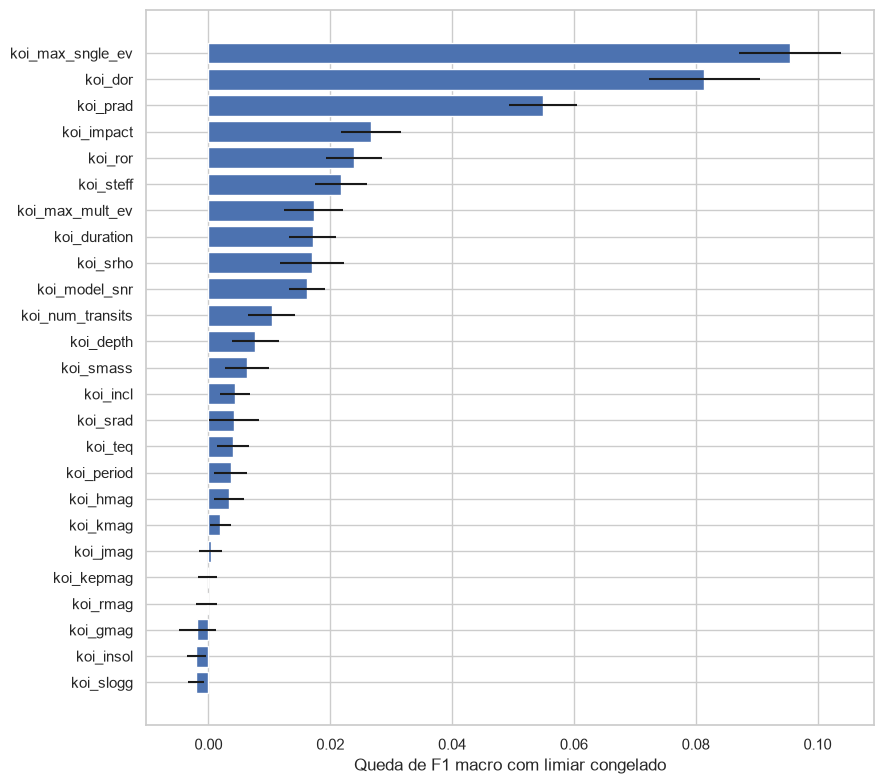

,atributo,queda_media_f1,dp_permutacoes
7,koi_max_sngle_ev,0.095448,0.008393
16,koi_dor,0.081391,0.009110
10,koi_prad,0.054957,0.005541
11,koi_impact,0.026716,0.004886
15,koi_ror,0.023831,0.004578
19,koi_steff,0.021746,0.004285
8,koi_max_mult_ev,0.017254,0.004818
12,koi_duration,0.017103,0.003886
24,koi_srho,0.016957,0.005245
9,koi_model_snr,0.016171,0.002880


In [30]:
imp = permutation_importance(
    modelo_final,
    X_teste,
    y_teste,
    scoring=score_politica,
    n_repeats=20,
    random_state=SEMENTE,
    n_jobs=1,
)
importancias = pd.DataFrame(
    {
        "atributo": ATRIBUTOS,
        "queda_media_f1": imp.importances_mean,
        "dp_permutacoes": imp.importances_std,
    }
).sort_values("queda_media_f1")
plt.figure(figsize=(9, 8))
plt.barh(
    importancias.atributo,
    importancias.queda_media_f1,
    xerr=importancias.dp_permutacoes,
)
plt.xlabel("Queda de F1 macro com limiar congelado")
plt.tight_layout()
plt.show()
display(importancias.sort_values("queda_media_f1", ascending=False).head(10))


## 15. Registro final, leitura dos resultados e limitações

A conclusão abaixo é calculada a partir desta execução. O desvio entre treino e validação indica ajuste aos exemplos conhecidos, mas não basta para provar que uma configuração alternativa seria melhor. No k-NN, o desempenho de treino pode ser favorecido pela presença do próprio ponto entre os vizinhos.

O F1 atual não é comparado diretamente ao antigo 0,8459 como se ambos pertencessem ao mesmo experimento: mudaram a retenção de linhas incompletas, a partição, os espaços de busca e o limiar. Separar essas contribuições exigiria experimentos adicionais controlados. A ablação do PCA é a comparação controlada implementada aqui.

Permanecem limitações: rótulos históricos, ausência de validação externa, incertezas físicas não modeladas, uma partição externa de cinco folds, orçamento finito de busca e proveniência incompleta do recorte. A análise não permite inferir causalidade, habitabilidade ou confirmação planetária. Resultados representam objetos deste recorte; extrapolação a outras missões exige avaliação específica.

In [31]:
tn, fp, fn, tp = confusion_matrix(y_teste, pred_teste, labels=[0, 1]).ravel()
media_auto = externa.loc[
    externa.familia == "Seleção automática", "f1_macro"
].mean()
dp_auto = externa.loc[
    externa.familia == "Seleção automática", "f1_macro"
].std()


### Escrevendo a conclusão

A conclusão é construída com os resultados calculados, sem inserir métricas manualmente.

As contagens da matriz de confusão e as métricas alimentam o texto exibido ao final. Além da conclusão, são exportadas tabelas de avaliação, cenários de limiar, curvas de aprendizado, importâncias e previsões individuais. Esses arquivos permitem consultar os resultados sem repetir todo o treinamento. A conclusão descreve a concordância com os rótulos do catálogo e não constitui uma confirmação física de novos exoplanetas.

In [32]:
texto = (
    f"**Resultado desta execução.** O procedimento de seleção automática obteve F1 macro externo "
    f"{media_auto:.4f} ± {dp_auto:.4f} (média ± DP entre folds). A busca final escolheu "
    f"**{familia_final}**, com limiar **{limiar_final:.3f}**. No holdout retrospectivo, "
    f'F1 macro = **{resultado_teste["f1_macro"]:.4f}**, precisão dos candidatos = '
    f'{resultado_teste["precisao_candidato"]:.2%} e recall = {resultado_teste["recall_candidato"]:.2%}. '
    f"Foram recuperados {tp} candidatos e rejeitados {fn}; {fp} falsos positivos foram "
    f"marcados como candidatos e {tn} foram rejeitados corretamente. "
    "Essas contagens medem concordância com o catálogo, sem confirmar novos planetas."
)
display(Markdown(texto))
(SAIDA / "conclusao.md").write_text(texto)
resumo.to_csv(SAIDA / "resumo_externo.csv")
intervalos.to_csv(SAIDA / "intervalos_teste.csv")
relatorio.to_csv(SAIDA / "relatorio_classes.csv")
cenarios.to_csv(SAIDA / "cenarios_limiar.csv", index=False)
curvas.to_csv(SAIDA / "curvas_aprendizado.csv", index=False)
importancias.to_csv(SAIDA / "importancias.csv", index=False)
pd.DataFrame(historico_buscas).to_json(
    SAIDA / "resumo_buscas.json", orient="records", indent=2, force_ascii=False
)
pd.DataFrame(
    {
        "kepid": g_teste,
        "kepoi_name": dados.iloc[idx_teste][OBJETO].to_numpy(),
        "y": y_teste,
        "prob": prob_teste,
        "pred": pred_teste,
    }
).to_csv(SAIDA / "previsoes_teste.csv", index=False)
print("Artefatos de reprodução:", SAIDA)
print("Tentativas completas:", sum(i["completas"] for i in historico_buscas))
print(
    "Configurações distintas por estudo: ver resumo_buscas.json; não somar como unicidade global."
)


**Resultado desta execução.** O procedimento de seleção automática obteve F1 macro externo 0.8459 ± 0.0034 (média ± DP entre folds). A busca final escolheu **Boosting**, com limiar **0.500**. No holdout retrospectivo, F1 macro = **0.8801**, precisão dos candidatos = 84.41% e recall = 86.20%. Foram recuperados 406 candidatos e rejeitados 65; 75 falsos positivos foram marcados como candidatos e 684 foram rejeitados corretamente. Essas contagens medem concordância com o catálogo, sem confirmar novos planetas.

Artefatos de reprodução: resultados_tiamat\126d5f8ed9a5
Tentativas completas: 3600
Configurações distintas por estudo: ver resumo_buscas.json; não somar como unicidade global.


## 16. Referências

[1] NASA. **What's a transit?** <https://science.nasa.gov/exoplanets/whats-a-transit/>

[2] THOMPSON, S. E. et al. **Planetary Candidates Observed by Kepler. VIII. A Fully Automated Catalog with Measured Completeness and Reliability Based on Data Release 25.** The Astrophysical Journal Supplement Series, 235, 38, 2018. DOI: <https://doi.org/10.3847/1538-4365/aab4f9> . Texto: <https://arxiv.org/abs/1710.06758>

[3] NASA EXOPLANET ARCHIVE. **Data Columns in Kepler Objects of Interest Table.** <https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html> . Definições físicas complementares: <https://exoplanetarchive.ipac.caltech.edu/docs/TableColumnDescriptors.html>

[4] SEAGER, S.; MALLÉN-ORNELAS, G. **A Unique Solution of Planet and Star Parameters from an Extrasolar Planet Transit Light Curve.** The Astrophysical Journal, 585, p. 1038–1055, 2003. DOI: <https://doi.org/10.1086/346105> . Preprint: <https://arxiv.org/abs/astro-ph/0206228>

[5] SHALLUE, C. J.; VANDERBURG, A. **Identifying Exoplanets with Deep Learning: A Five-planet Resonant Chain around Kepler-80 and an Eighth Planet around Kepler-90.** The Astronomical Journal, 155, 94, 2018. DOI: <https://doi.org/10.3847/1538-3881/aa9e09> . <https://arxiv.org/abs/1712.05044>

[6] SCIKIT-LEARN. **Common pitfalls and recommended practices.** <https://scikit-learn.org/stable/common_pitfalls.html>

[7] SCIKIT-LEARN. **SimpleImputer.** <https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html>

[8] SCIKIT-LEARN. **StratifiedGroupKFold.** <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html>

[9] SCIKIT-LEARN. **Nested versus non-nested cross-validation.** <https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html> . Complemento: <https://scikit-learn.org/stable/modules/cross_validation.html>

[10] SCIKIT-LEARN. **StandardScaler.** <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html>

[11] SCIKIT-LEARN. **DummyClassifier.** <https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html>

[12] SCIKIT-LEARN. **LogisticRegression; Linear Models.** <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html> ; <https://scikit-learn.org/stable/modules/linear_model.html>

[13] SCIKIT-LEARN. **KNeighborsClassifier.** <https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html>

[14] SCIKIT-LEARN. **PCA.** <https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html>

[15] SCIKIT-LEARN. **DecisionTreeClassifier; Decision Trees.** <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html> ; <https://scikit-learn.org/stable/modules/tree.html>

[16] SCIKIT-LEARN. **f1_score.** <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html>

[17] SCIKIT-LEARN. **average_precision_score.** <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html>

[18] SCIKIT-LEARN. **Tuning the decision threshold for class prediction.** <https://scikit-learn.org/stable/modules/classification_threshold.html>

[19] SCIKIT-LEARN. **RandomForestClassifier; Ensembles.** <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html> ; <https://scikit-learn.org/stable/modules/ensemble.html>

[20] SCIKIT-LEARN. **HistGradientBoostingClassifier.** <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html>

[21] OPTUNA. **TPESampler; Study.** <https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html> ; <https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html>

[22] SCIKIT-LEARN. **learning_curve.** <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html>

[23] SHALIZI, C. R. **The Bootstrap.** 36-402 Advanced Data Analysis, Carnegie Mellon University, 3 fev. 2011. Especialmente a discussão de dados dependentes. <https://www.stat.cmu.edu/~cshalizi/402/lectures/08-bootstrap/lecture-08.pdf>

[24] SCIKIT-LEARN. **Permutation feature importance.** <https://scikit-learn.org/stable/modules/permutation_importance.html>

[25] BENGIO, Y.; GRANDVALET, Y. **No Unbiased Estimator of the Variance of K-Fold Cross-Validation.** Journal of Machine Learning Research, v. 5, p. 1089–1105, 2004. <https://www.jmlr.org/papers/v5/grandvalet04a.html>

## 17. Uso de IA e registro da revisão

Durante o desenvolvimento deste projeto, ferramentas de Inteligência Artificial foram utilizadas como um apoio prático e complementar, ajudando a agilizar a montagem dos códigos, a tirar dúvidas sobre o funcionamento das bibliotecas e a revisar os textos explicativos do caderno, também foi usada para encontrar o datase a na contextualização do problema científico. Link: https://chatgpt.com/share/6af42d76-9d78-83e9-9aa6-a3c556bc0604

- O código foi dividido em etapas e formatado com operações explícitas, preservando a ordem dos cálculos. A comparação da árvore sintática abstrata confirmou a equivalência de todo o código antes e depois da adaptação.
- As 34 saídas do arquivo recebido foram preservadas integralmente, incluindo imagens, tabelas e mensagens. Os contadores de execução foram limpos para não sugerir uma nova execução completa.
- A leitura, o tratamento e a divisão foram executados na conferência: 6.148 registros, 25 atributos, 4.918 registros de desenvolvimento e 1.230 de teste.
- O Boosting foi reajustado usando a configuração vencedora registrada no notebook original, sem realizar outra busca. O F1 macro obtido foi 0,8752916667, a precisão dos candidatos foi 0,8323108384 e o recall foi 0,8641188960, compatíveis com as saídas recebidas.
- As 3.600 tentativas de otimização não foram reexecutadas nesta adaptação. As saídas preservadas documentam a execução anterior; executar todas as células as substituirá pelos resultados do ambiente utilizado.

**Relação com as aulas:** pandas (1.1), k-NN e métricas (2.1), divisão dos dados (2.2), baseline e modelo linear (3.0), árvores e florestas (4.0), classificação (5.0 e 9.0), validação e vazamento (6.0 e 6.1), pipelines (7.0), Optuna (7.1) e PCA (8.0). As explicações precedem os blocos de código, seguindo a organização dos exemplos guiados. Validação aninhada por estrelas, bootstrap e Boosting foram mantidos como extensões do projeto original, pois removê-los mudaria os resultados solicitados.